# Meal-prep Pareto frontier: divide and conquer
**COT5405 Project 1 — Nicholas Tayag**

Find every fixed-portion meal for which no alternative costs no more, provides
at least as much protein, and strictly improves one of these attributes.
This notebook contains the complete implementation, validation, reproducible
runtime experiments, and figures for the report. Run the cells from top to bottom.

The eight-meal illustration uses **hypothetical values**. All large inputs are
**synthetic complexity experiments**, not measured recipes. Replace the small
illustration with documented meal measurements if the report needs an empirical
food case study. The algorithm selects a shortlist, not a weekly diet.

The green mean/standard-deviation markers and red theoretical curve follow the
visual convention in [Sam's notebook](https://github.com/samuelcohen1/song-scheduling-project).
For algorithm background, see [Börzsönyi, Kossmann, and Stocker, *The Skyline Operator*
(ICDE 2001)](https://www.cs.ucr.edu/~tsotras/cs236/W15/skyline-operator.pdf).
The implementation below uses the merge-based variant described in our report.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import os
import platform
import sys
from datetime import datetime
from zoneinfo import ZoneInfo
from IPython.display import display, Markdown
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 12)
pd.set_option("display.precision", 6)
print("Python:", sys.version.split()[0])
print("Executable:", sys.executable)
print("Outputs:", OUTPUT_DIR.resolve())

Matplotlib is building the font cache; this may take a moment.


Python: 3.12.14
Executable: <project-directory>/.venv/bin/python
Outputs: <project-directory>/output


## 1. Algorithm

Records use integer **cents** and **milligrams of protein** to make equality exact
at the chosen precision. Convert documented measurements to these units once;
comparisons then apply to the recorded values. Meal IDs must be unique, but
different IDs may have identical attributes. Filter preferences and allergies
before computing the frontier.

Split the input into balanced halves without sorting it first. Recursively return
each half's frontier in cost order. Merge the sorted frontiers and process entire
equal-cost groups. Keep all meals attaining a group's maximum protein only if
that value exceeds the maximum among strictly cheaper groups.

A dominated meal cannot become nondominated when more meals are added. By
transitivity, a surviving local dominator can replace a removed dominator in
cross-half comparisons. The merge then computes the exact frontier of the union.

Each merge costs at most linear time in the input size. There are $O(\log n)$
levels, giving $O(n\log n)$ time, with a tight $\Theta(n\log n)$ worst case when
all meals survive. Auxiliary space is $O(n)$. The pairwise function is an
independent reference with $\Theta(n^2)$ worst-case time.

In [2]:
"""Two-objective meal skyline: minimize cost, maximize protein.

All records describe fixed servings. Cost uses integer cents and protein uses
integer milligrams so equality is exact at the chosen input precision.
Distinct meal IDs with identical nondominated attributes are all retained.
"""

from dataclasses import dataclass
from collections.abc import Sequence


@dataclass(frozen=True, slots=True)
class Meal:
    meal_id: str
    cost_cents: int
    protein_mg: int

    def __post_init__(self):
        if not isinstance(self.meal_id, str) or not self.meal_id.strip():
            raise ValueError("meal_id must be a nonempty string")
        for name in ("cost_cents", "protein_mg"):
            value = getattr(self, name)
            if type(value) is not int:
                raise TypeError(f"{name} must be a Python integer")
            if value < 0:
                raise ValueError(f"{name} must be nonnegative")


def _validate_meals(meals: Sequence[Meal]) -> None:
    seen = set()
    for meal in meals:
        if not isinstance(meal, Meal):
            raise TypeError("Every input record must be a Meal")
        if meal.meal_id in seen:
            raise ValueError(f"Duplicate meal ID: {meal.meal_id}")
        seen.add(meal.meal_id)


def _combine_frontiers(left: list[Meal], right: list[Meal]) -> list[Meal]:
    """Linear merge and equal-cost filtering; both inputs are cost-sorted."""
    merged = []
    i = j = 0
    while i < len(left) and j < len(right):
        if left[i].cost_cents <= right[j].cost_cents:
            merged.append(left[i])
            i += 1
        else:
            merged.append(right[j])
            j += 1
    merged.extend(left[i:])
    merged.extend(right[j:])

    frontier = []
    best_protein = -1  # Every valid protein value is nonnegative.
    start = 0
    while start < len(merged):
        cost = merged[start].cost_cents
        stop = start
        group_max = -1
        while stop < len(merged) and merged[stop].cost_cents == cost:
            group_max = max(group_max, merged[stop].protein_mg)
            stop += 1

        # best_protein includes strictly cheaper groups only.
        if group_max > best_protein:
            for k in range(start, stop):
                if merged[k].protein_mg == group_max:
                    frontier.append(merged[k])
        best_protein = max(best_protein, group_max)
        start = stop
    return frontier


def meal_frontier(meals: Sequence[Meal]) -> list[Meal]:
    """Return every nondominated record, sorted by nondecreasing cost.

    The input is not modified. Splits use index ranges (no global presort).
    Worst-case time is Theta(n log n), auxiliary space O(n), recursion O(log n).
    Linear input validation is included in the public operation and its timing.
    """
    _validate_meals(meals)

    def solve(lo: int, hi: int) -> list[Meal]:
        if hi - lo <= 1:
            return [] if lo == hi else [meals[lo]]
        mid = (lo + hi) // 2
        left = solve(lo, mid)
        right = solve(mid, hi)
        return _combine_frontiers(left, right)

    return solve(0, len(meals))


def brute_force_frontier(meals: Sequence[Meal]) -> list[Meal]:
    """Independent pairwise reference; worst-case Theta(n squared)."""
    _validate_meals(meals)
    frontier = []
    for meal in meals:
        dominated = False
        for other in meals:
            if (
                other.cost_cents <= meal.cost_cents
                and other.protein_mg >= meal.protein_mg
                and (
                    other.cost_cents < meal.cost_cents
                    or other.protein_mg > meal.protein_mg
                )
            ):
                dominated = True
                break
        if not dominated:
            frontier.append(meal)
    return sorted(frontier, key=lambda meal: meal.cost_cents)

## 2. Correctness checks

The reference checks the dominance definition directly. We compare exact returned
IDs, sorted output, duplicate retention, and preservation of the input. Tests
include all 7,381 ordered inputs of length 0–4 from a 3×3 attribute grid, 300
random cases (also shuffled), named boundary cases, and invalid inputs.
Tests support the implementation; the written induction proof remains necessary.

In [3]:
"""Deterministic checks against an independent pairwise oracle."""

from itertools import product
import random



def run_validation_suite() -> dict:
    counts = {"named_cases": 0, "exhaustive_cases": 0,
              "random_cases": 0, "invalid_inputs": 0}

    def check(meals, expected=None):
        original = list(meals)
        result = meal_frontier(meals)
        oracle = brute_force_frontier(meals)
        result_ids = {m.meal_id for m in result}
        assert result_ids == {m.meal_id for m in oracle}
        assert len(result) == len(result_ids)
        assert result == sorted(result, key=lambda m: m.cost_cents)
        assert meals == original, "The algorithm mutated the input"
        assert all(m in meals for m in result)
        if expected is not None:
            assert result_ids == set(expected), (result_ids, expected)

    cases = [
        ([], set()),
        ([(0, 0)], {"0"}),
        ([(100, 20), (100, 30)], {"1"}),
        ([(100, 30), (200, 30)], {"0"}),
        ([(100, 30), (100, 30)], {"0", "1"}),
        ([(200, 20), (100, 30), (200, 20)], {"1"}),
        ([(100, 10), (200, 20), (300, 30)], {"0", "1", "2"}),
        ([(700, 40), (400, 20), (800, 38), (500, 30)], {"0", "1", "3"}),
        ([(600, 35), (800, 25), (400, 20), (700, 40),
          (500, 30), (600, 28), (800, 38), (900, 45)], {"0", "2", "3", "4", "7"}),
        ([(200, 30), (100, 20), (200, 30), (100, 20)], {"0", "1", "2", "3"}),
    ]
    for points, expected in cases:
        check([Meal(str(i), c, p) for i, (c, p) in enumerate(points)], expected)
        counts["named_cases"] += 1

    # All ordered inputs of length 0..4 over a 3x3 attribute grid.
    # This includes duplicate coordinates and every ordering across the split.
    grid = list(product(range(3), repeat=2))
    for size in range(5):
        for points in product(grid, repeat=size):
            check([Meal(str(i), c, p) for i, (c, p) in enumerate(points)])
            counts["exhaustive_cases"] += 1

    rng = random.Random(20261025)
    for _ in range(300):
        size = rng.randrange(101)
        meals = [Meal(str(i), rng.randrange(20), rng.randrange(20))
                 for i in range(size)]
        check(meals)
        expected = {m.meal_id for m in meal_frontier(meals)}
        rng.shuffle(meals)
        check(meals, expected)
        counts["random_cases"] += 1

    invalid = [
        (lambda: Meal("x", -1, 1), ValueError),
        (lambda: Meal("x", 1, -1), ValueError),
        (lambda: Meal("x", 1.5, 1), TypeError),
        (lambda: Meal("x", 1, float("nan")), TypeError),
        (lambda: Meal("x", True, 1), TypeError),
        (lambda: Meal("", 1, 1), ValueError),
        (lambda: meal_frontier([Meal("x", 1, 1), Meal("x", 2, 2)]), ValueError),
        (lambda: meal_frontier([("x", 1, 1)]), TypeError),
    ]
    for operation, error in invalid:
        try:
            operation()
        except error:
            counts["invalid_inputs"] += 1
        else:
            raise AssertionError(f"Expected {error.__name__}")

    counts["total_cases"] = sum(counts.values())
    return counts

In [4]:
validation_results = run_validation_suite()
print("All validation cases passed:")
display(pd.DataFrame([validation_results]))
(OUTPUT_DIR / "validation_results.json").write_text(
    json.dumps(validation_results, indent=2) + "\n")

All validation cases passed:


,named_cases,exhaustive_cases,random_cases,invalid_inputs,total_cases
0,10,7381,300,8,7699


121

## 3. Hypothetical meal example

This is the same eight-meal example used in the draft. The expected frontier is
**C, E, A, D, H**, in increasing cost order. B, F, and G are dominated.
Neither these prices nor these nutrient values were collected from food sources.

In [5]:
example_meals = [
    Meal("A", 600, 35000), Meal("B", 800, 25000),
    Meal("C", 400, 20000), Meal("D", 700, 40000),
    Meal("E", 500, 30000), Meal("F", 600, 28000),
    Meal("G", 800, 38000), Meal("H", 900, 45000),
]
example_frontier = meal_frontier(example_meals)
assert [m.meal_id for m in example_frontier] == ["C", "E", "A", "D", "H"]
selected_ids = {m.meal_id for m in example_frontier}
example_table = pd.DataFrame([
    {"meal_id": m.meal_id, "cost_cents": m.cost_cents,
     "protein_mg": m.protein_mg, "cost_dollars": m.cost_cents / 100,
     "protein_grams": m.protein_mg / 1000,
     "result": "Keep" if m.meal_id in selected_ids else "Remove",
     "data_status": "hypothetical"}
    for m in example_meals
])
display(example_table)
example_table.to_csv(OUTPUT_DIR / "hypothetical_meals.csv", index=False)

,meal_id,cost_cents,protein_mg,cost_dollars,protein_grams,result,data_status
0,A,600,35000,6.0,35.0,Keep,hypothetical
1,B,800,25000,8.0,25.0,Remove,hypothetical
2,C,400,20000,4.0,20.0,Keep,hypothetical
3,D,700,40000,7.0,40.0,Keep,hypothetical
4,E,500,30000,5.0,30.0,Keep,hypothetical
5,F,600,28000,6.0,28.0,Remove,hypothetical
6,G,800,38000,8.0,38.0,Remove,hypothetical
7,H,900,45000,9.0,45.0,Keep,hypothetical


## 4. Experimental and plotting helpers

The following functions generate inputs, measure complete public function calls,
summarize observations, and save both PNG and SVG figures. All experiment code is
included here so this notebook can run without importing the companion modules.

In [6]:
"""Input generation, honest timing summaries, and report figures."""

import gc
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


GREEN = "#2c6e49"
RED = "#bc4749"
FAMILY_LABELS = {
    "all_frontier": "All meals nondominated (worst case)",
    "random": "Independent random cost and protein",
    "dominated_chain": "Dominance chain (one survivor)",
}


def synthetic_meals(n, family, seed):
    """Synthetic complexity inputs, not measured food or price data."""
    rng = random.Random(seed)
    if family == "all_frontier":
        points = [(i + 1, i + 1) for i in range(n)]
    elif family == "dominated_chain":
        points = [(i + 1, n - i) for i in range(n)]
    elif family == "random":
        points = [(rng.randrange(1, 10 * n + 1),
                   rng.randrange(1, 10 * n + 1)) for _ in range(n)]
    else:
        raise ValueError(f"Unknown input family: {family}")
    meals = [Meal(str(i), c, p) for i, (c, p) in enumerate(points)]
    rng.shuffle(meals)
    return meals


def measure_one_input(function, meals, repeats=3, target_seconds=0.005):
    """One warm-up/calibration, then repeated batches on the same input.

    Returned times are per complete function call, including validation.
    Cyclic GC is temporarily disabled; normal reference counting stays on.
    All observations are retained. No outliers are removed.
    """
    gc.collect()
    was_enabled = gc.isenabled()
    gc.disable()
    try:
        start = time.perf_counter_ns()
        warmup_result = function(meals)
        warmup_seconds = (time.perf_counter_ns() - start) / 1e9
        output_size = len(warmup_result)
        del warmup_result
        batch_size = max(1, min(128, math.ceil(
            target_seconds / max(warmup_seconds, 1e-9))))
        observations = []
        for repeat in range(repeats):
            start = time.perf_counter_ns()
            for _ in range(batch_size):
                result = function(meals)
            elapsed_ns = time.perf_counter_ns() - start
            assert len(result) == output_size
            observations.append({
                "repeat": repeat,
                "batch_size": batch_size,
                "elapsed_ns": elapsed_ns,
                "seconds_per_call": elapsed_ns / 1e9 / batch_size,
                "output_size": output_size,
            })
        return observations
    finally:
        if was_enabled:
            gc.enable()


def benchmark(sizes, families, seed_count=7, repeats=3,
              master_seed=20261025, include_brute_force=False):
    """Randomized job order; generation, warm-up and checks are not timed."""
    algorithms = {"divide_and_conquer": meal_frontier}
    if include_brute_force:
        algorithms["brute_force"] = brute_force_frontier
    jobs = [(family, n, trial, name)
            for family in families for n in sizes
            for trial in range(seed_count) for name in algorithms]
    random.Random(master_seed).shuffle(jobs)
    rows = []
    family_numbers = {name: i for i, name in enumerate(FAMILY_LABELS)}
    for job_index, (family, n, trial, algorithm) in enumerate(jobs, start=1):
        seed = master_seed + family_numbers[family] * 10**9 + n * 100 + trial
        meals = synthetic_meals(n, family, seed)
        observations = measure_one_input(algorithms[algorithm], meals, repeats)
        size = observations[0]["output_size"]
        if family == "all_frontier":
            assert size == n
        elif family == "dominated_chain":
            assert size == 1
        for observation in observations:
            rows.append({"algorithm": algorithm, "family": family,
                         "n": n, "trial": trial, "seed": seed,
                         **observation})
        if job_index % 21 == 0 or job_index == len(jobs):
            print(f"Completed {job_index}/{len(jobs)} benchmark inputs", flush=True)
    return pd.DataFrame(rows).sort_values(
        ["algorithm", "family", "n", "trial", "repeat"]).reset_index(drop=True)


def summarize_timings(raw):
    """Median of 3 batches per seed; mean and sample SD across 7 seeds."""
    keys = ["algorithm", "family", "n", "trial", "seed"]
    per_seed = raw.groupby(keys, as_index=False).agg(
        seconds=("seconds_per_call", "median"),
        output_size=("output_size", "first"),
    )
    summary = per_seed.groupby(["algorithm", "family", "n"], as_index=False).agg(
        mean_seconds=("seconds", "mean"),
        std_seconds=("seconds", "std"),
        min_seconds=("seconds", "min"),
        max_seconds=("seconds", "max"),
        seed_count=("seconds", "count"),
        mean_frontier_size=("output_size", "mean"),
    )
    return per_seed, summary


def save_figure(fig, output_dir, stem):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_dir / f"{stem}.png", dpi=220, bbox_inches="tight")
    fig.savefig(output_dir / f"{stem}.svg", bbox_inches="tight")
    return fig


def plot_meal_example(meals, frontier, output_dir):
    """Before/after graphic: all eight hypothetical meals and five survivors."""
    selected = {m.meal_id for m in frontier}
    fig, axes = plt.subplots(1, 2, figsize=(11.8, 5.0), sharex=True, sharey=True)
    for ax in axes:
        ax.set_xlim(3.5, 9.6)
        ax.set_ylim(15, 50)
        ax.set_xlabel("Cost per fixed serving ($)")
        ax.grid(linestyle=":", alpha=0.35)
        ax.set_axisbelow(True)
        for meal in meals:
            x, y = meal.cost_cents / 100, meal.protein_mg / 1000
            kept = meal.meal_id in selected
            color = "#4c72b0" if ax is axes[0] else GREEN if kept else RED
            marker = "o" if ax is axes[0] or kept else "x"
            ax.scatter(x, y, s=80, color=color, marker=marker, zorder=3)
            ax.annotate(meal.meal_id, (x, y), xytext=(7, 5),
                        textcoords="offset points", fontsize=11, weight="bold")
    axes[0].set_ylabel("Protein per fixed serving (g)")
    axes[0].set_title("Before: 8 candidate meals")
    axes[1].set_title("After: 5 nondominated meals")
    axes[1].plot([m.cost_cents / 100 for m in frontier],
                 [m.protein_mg / 1000 for m in frontier],
                 color=GREEN, alpha=0.65, linewidth=1.6, zorder=2)
    axes[1].scatter([], [], color=GREEN, s=65, label="Keep: C, E, A, D, H")
    axes[1].scatter([], [], color=RED, marker="x", s=65, label="Remove: B, F, G")
    axes[1].legend(loc="lower right", fontsize=9)
    fig.suptitle("Meal-prep trade-offs: before and after divide and conquer",
                 fontsize=14, weight="bold")
    fig.text(0.5, 0.015,
             "Hypothetical values. The connecting line is a visual guide; only plotted meals are available.",
             ha="center", fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.05, 1, 0.95))
    return save_figure(fig, output_dir, "before_after_meals")


def fit_reference(summary):
    worst = summary[(summary.algorithm == "divide_and_conquer") &
                    (summary.family == "all_frontier")].sort_values("n")
    n = worst.n.to_numpy(dtype=float)
    means = worst.mean_seconds.to_numpy()
    x = n * np.log2(n)
    # One least-squares scale, through the origin, fitted to all measured sizes.
    k = float(np.dot(x, means) / np.dot(x, x))
    return worst, k


def plot_runtime(summary, output_dir):
    worst, k = fit_reference(summary)
    n = worst.n.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(8.5, 5.6))
    ax.errorbar(n, worst.mean_seconds, yerr=worst.std_seconds,
                fmt="o-", color=GREEN, ecolor="#6a994e", linewidth=2,
                markersize=6, capsize=4, label="Measured mean ± sample SD (7 seeds)")
    dense = np.geomspace(n[0], n[-1], 250)
    ax.plot(dense, k * dense * np.log2(dense), "--", color=RED, linewidth=2,
            label=r"Scaled $k n\log_2 n$ (one least-squares fit)")
    ax.set(xscale="log", yscale="log", xlabel="Number of candidate meals, n",
           ylabel="Runtime per call (seconds)",
           title="Meal frontier runtime: all meals nondominated")
    ax.grid(True, which="both", linestyle=":", alpha=0.45)
    ax.legend(loc="upper left", fontsize=9)
    fig.text(0.5, 0.015, "Each seed contributes the median of 3 timed batches; input generation is excluded.",
             ha="center", fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return save_figure(fig, output_dir, "runtime_nlogn")


def plot_normalized(summary, output_dir):
    worst, k = fit_reference(summary)
    n = worst.n.to_numpy(dtype=float)
    denominator = n * np.log2(n)
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.errorbar(n, worst.mean_seconds / denominator * 1e9,
                yerr=worst.std_seconds / denominator * 1e9,
                fmt="o-", color=GREEN, capsize=4,
                label="Normalized mean ± sample SD")
    ax.axhline(k * 1e9, linestyle="--", color=RED, label="Fitted reference constant k")
    ax.set(xscale="log", xlabel="Number of candidate meals, n",
           ylabel=r"$t(n)/(n\log_2 n)$ (nanoseconds)",
           title="Normalized runtime: all meals nondominated")
    ax.grid(True, which="both", linestyle=":", alpha=0.4)
    ax.legend(fontsize=9)
    fig.tight_layout()
    return save_figure(fig, output_dir, "runtime_normalized")


def plot_families(summary, output_dir):
    fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.8))
    colors = [GREEN, "#4c72b0", "#b57426"]
    for (family, label), color in zip(FAMILY_LABELS.items(), colors):
        part = summary[(summary.family == family) &
                       (summary.algorithm == "divide_and_conquer")].sort_values("n")
        axes[0].errorbar(part.n, part.mean_seconds, yerr=part.std_seconds,
                         fmt="o-", color=color, capsize=3, label=label, markersize=4)
        axes[1].plot(part.n, part.mean_frontier_size, "o-", color=color, markersize=4)
    for ax in axes:
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Number of candidate meals, n")
        ax.grid(True, which="both", linestyle=":", alpha=0.35)
    axes[0].set(title="Runtime depends on the input", ylabel="Runtime per call (seconds)")
    axes[1].set(title="Number of meals in the output", ylabel="Mean frontier size")
    axes[0].legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    return save_figure(fig, output_dir, "runtime_input_families")


def plot_baseline(summary, output_dir):
    fig, ax = plt.subplots(figsize=(8.5, 5.0))
    for name, color, label in [("divide_and_conquer", GREEN, "Divide and conquer"),
                               ("brute_force", RED, "Pairwise reference")]:
        part = summary[summary.algorithm == name].sort_values("n")
        ax.errorbar(part.n, part.mean_seconds, yerr=part.std_seconds,
                    fmt="o-", color=color, capsize=4, label=label)
    ax.set(xscale="log", yscale="log", xlabel="Number of candidate meals, n",
           ylabel="Runtime per call (seconds)",
           title="Divide and conquer vs. pairwise comparison\nAll meals nondominated; identical seeded inputs")
    ax.grid(True, which="both", linestyle=":", alpha=0.4)
    ax.legend()
    fig.tight_layout()
    return save_figure(fig, output_dir, "runtime_vs_bruteforce")

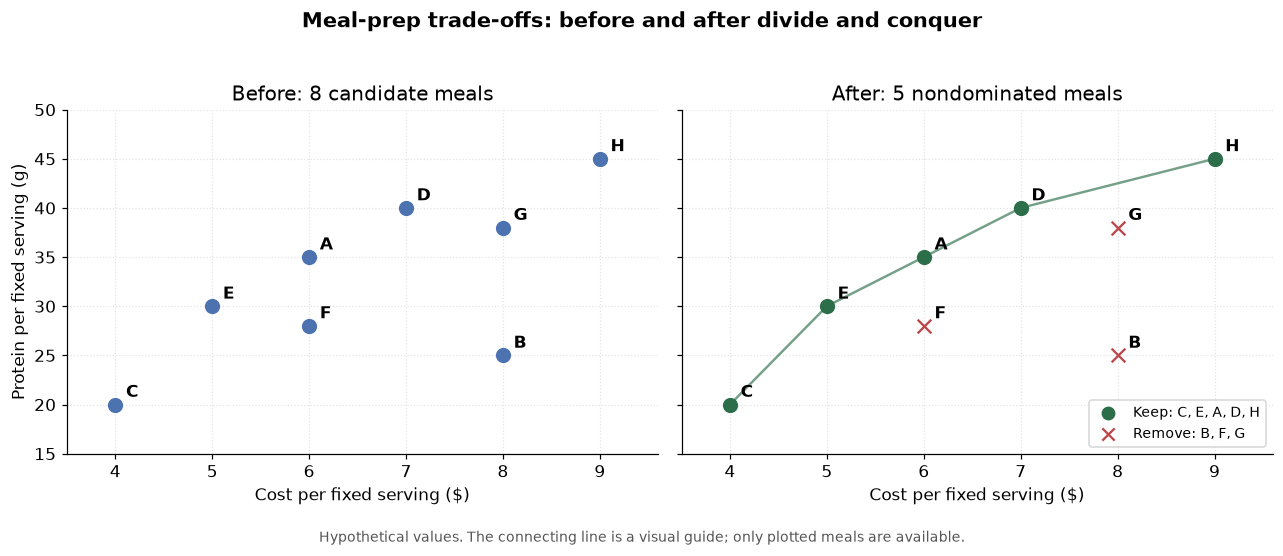

In [7]:
fig = plot_meal_example(example_meals, example_frontier, OUTPUT_DIR)
plt.show()
plt.close(fig)

## 5. Runtime experiment design

- **Sizes:** $2^6$ through $2^{17}$ (64–131,072 meals).
- **Seven seeded instances per size and family**, each measured in three batches.
  Each batch averages complete calls over a calibrated count of 1–128 iterations,
  targeting about 5 ms for small inputs. Each seed contributes its median batch
  time. Plot markers show the mean across seven seed medians; error bars show the
  **sample standard deviation**, not a confidence interval.
- A warm-up/calibration call precedes timing. Construction, shuffling, correctness
  checks, file output, and plotting are excluded. The public algorithm's linear
  validation, recursion, merges, and filtering are included. Cyclic GC is disabled
  during measurements and restored afterward; reference counting remains active.
- Job order is randomized to reduce systematic ordering effects. Every observation
  is saved; none is removed as an outlier. Timings still depend on system load,
  allocation, caching, and clock behavior.
- **All-frontier:** costs and protein both increase, so all $n$ records survive.
  Seven instances differ by input permutation. This is the worst-case family.
- **Random:** cost and protein are independently generated integers. These inputs
  often have small frontiers and need not follow worst-case growth.
- **Dominance chain:** increasing cost and decreasing protein; each recursive
  subset has one survivor. This implementation can process this family in linear
  time because its combination steps remain small.

The red reference uses **one least-squares scale** $k$ fitted through the origin
to all measured worst-case means: $k=\sum x_i t_i / \sum x_i^2$ where
$x_i=n_i\log_2 n_i$. It is a visual comparison, not a complexity proof. It does
not force every point to match. A normalized plot makes deviations visible.

In [8]:
SIZES = [2**power for power in range(6, 18)]
FAMILIES = ["all_frontier", "random", "dominated_chain"]
SEED_COUNT = 7
REPEATS = 3
MASTER_SEED = 20261025
SOURCE_SHA256 = {'meal_frontier.py': '6a03f44f76f812730bb6dc0eda0b2e95fddb8aba04fb5168a35b8870de054f54', 'validation.py': '569b7a8732941c9b05e06350dffd2234a85af92d03356715bdf35bc7a915c168', 'experiment_helpers.py': 'dae3af4315144159b2eda03d1ddad7f9113dcce3898532c9e92dd5844bb806a9'}

experiment_started = datetime.now(ZoneInfo("America/New_York")).isoformat()
metadata = {
    "experiment_started": experiment_started,
    "timezone": "America/New_York",
    "python": sys.version,
    "platform": platform.platform(),
    "machine": platform.machine(),
    "logical_cpu_count": os.cpu_count(),
    "packages": {name: importlib.metadata.version(name) for name in
        ("numpy", "pandas", "matplotlib", "nbformat", "nbclient", "ipykernel")},
    "sizes": SIZES, "families": FAMILIES,
    "seed_count": SEED_COUNT, "repeats_per_seed": REPEATS,
    "master_seed": MASTER_SEED,
    "batch_target_seconds": 0.005, "batch_max_calls": 128,
    "timer": "time.perf_counter_ns", "cyclic_gc_during_timing": False,
    "summary": "mean and sample SD of seven per-seed median batch times",
    "curve_scaling": "one least-squares factor through origin across all sizes",
    "source_sha256_at_notebook_build": SOURCE_SHA256,
    "data_status": "hypothetical meal example; synthetic timing inputs",
}
print("Main experiment:", len(SIZES) * len(FAMILIES) * SEED_COUNT,
      "seeded inputs,", REPEATS, "timed batches each")

Main experiment: 252 seeded inputs, 3 timed batches each


In [9]:
runtime_raw = benchmark(SIZES, FAMILIES, SEED_COUNT, REPEATS, MASTER_SEED)
runtime_per_seed, runtime_summary = summarize_timings(runtime_raw)
runtime_raw.to_csv(OUTPUT_DIR / "runtime_raw.csv", index=False)
runtime_per_seed.to_csv(OUTPUT_DIR / "runtime_per_seed.csv", index=False)
runtime_summary.to_csv(OUTPUT_DIR / "runtime_summary.csv", index=False)
display(runtime_summary)

Completed 21/252 benchmark inputs


Completed 42/252 benchmark inputs


Completed 63/252 benchmark inputs


Completed 84/252 benchmark inputs


Completed 105/252 benchmark inputs


...

Completed 189/252 benchmark inputs


Completed 210/252 benchmark inputs


Completed 231/252 benchmark inputs


Completed 252/252 benchmark inputs


,algorithm,family,n,mean_seconds,std_seconds,min_seconds,max_seconds,seed_count,mean_frontier_size
0,divide_and_conquer,all_frontier,64,0.000085,3.528432e-06,0.000083,0.000093,7,64.000000
1,divide_and_conquer,all_frontier,128,0.000194,1.405770e-06,0.000192,0.000196,7,128.000000
2,divide_and_conquer,all_frontier,256,0.000437,1.504396e-06,0.000435,0.000439,7,256.000000
3,divide_and_conquer,all_frontier,512,0.001009,7.785037e-06,0.000994,0.001020,7,512.000000
4,divide_and_conquer,all_frontier,1024,0.002267,6.540414e-05,0.002230,0.002414,7,1024.000000
5,divide_and_conquer,all_frontier,2048,0.004917,2.251513e-05,0.004894,0.004960,7,2048.000000
6,divide_and_conquer,all_frontier,4096,0.011212,1.253488e-03,0.010700,0.014053,7,4096.000000
7,divide_and_conquer,all_frontier,8192,0.023334,1.479944e-04,0.023136,0.023601,7,8192.000000
8,divide_and_conquer,all_frontier,16384,0.050423,8.300189e-04,0.049692,0.051869,7,16384.000000
9,divide_and_conquer,all_frontier,32768,0.109465,1.722777e-03,0.107734,0.112832,7,32768.000000


## 6. Measured runtime and normalized growth

The first figure matches Sam's green measurement / red theoretical-reference
convention. The second displays the normalized measurements without hiding
deviations from the fitted curve. A third compares the three input families
and their frontier sizes.

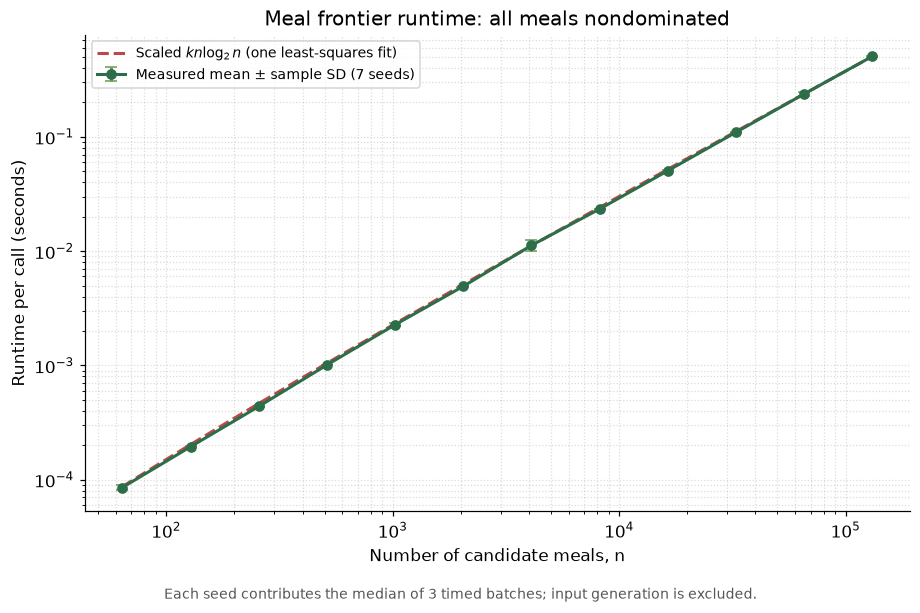

In [10]:
fig = plot_runtime(runtime_summary, OUTPUT_DIR)
plt.show()
plt.close(fig)

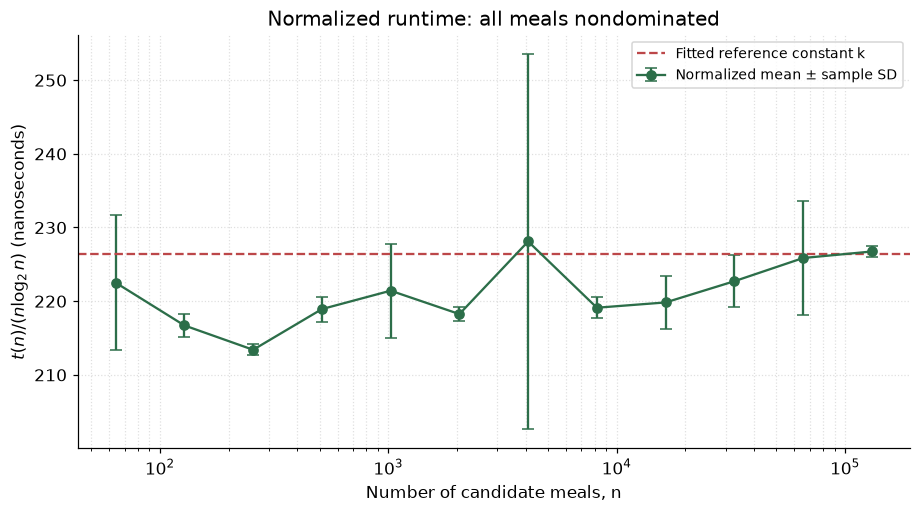

In [11]:
fig = plot_normalized(runtime_summary, OUTPUT_DIR)
plt.show()
plt.close(fig)

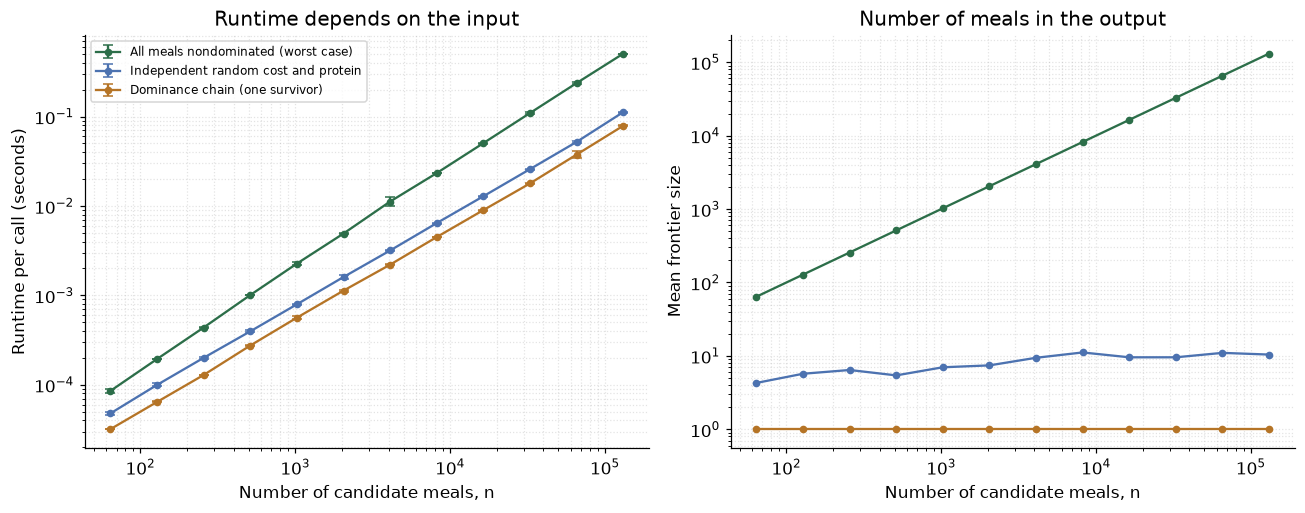

In [12]:
fig = plot_families(runtime_summary, OUTPUT_DIR)
plt.show()
plt.close(fig)

## 7. Pairwise reference comparison on smaller inputs

Both methods receive identical seeded all-frontier inputs at sizes 32–2,048.
This makes the pairwise method examine every candidate against every other
candidate and avoids misleading timings caused by early exits on dominated data.
The quadratic reference is deliberately limited to smaller sizes.

Completed 21/98 benchmark inputs


Completed 42/98 benchmark inputs


Completed 63/98 benchmark inputs


Completed 84/98 benchmark inputs


Completed 98/98 benchmark inputs


,algorithm,family,n,mean_seconds,std_seconds,min_seconds,max_seconds,seed_count,mean_frontier_size
0,brute_force,all_frontier,32,0.000016,1.957547e-07,0.000015,0.000016,7,32.0
1,brute_force,all_frontier,64,0.000056,4.470437e-07,0.000056,0.000057,7,64.0
2,brute_force,all_frontier,128,0.000214,2.093728e-06,0.000211,0.000217,7,128.0
3,brute_force,all_frontier,256,0.000827,1.027052e-05,0.000815,0.000842,7,256.0
4,brute_force,all_frontier,512,0.003797,6.031180e-05,0.003724,0.003872,7,512.0
5,brute_force,all_frontier,1024,0.014427,1.839330e-04,0.014229,0.014813,7,1024.0
6,brute_force,all_frontier,2048,0.055346,4.331961e-04,0.054656,0.055901,7,2048.0
7,divide_and_conquer,all_frontier,32,0.000037,2.793197e-07,0.000036,0.000037,7,32.0
8,divide_and_conquer,all_frontier,64,0.000086,1.101430e-06,0.000084,0.000088,7,64.0
9,divide_and_conquer,all_frontier,128,0.000195,5.956721e-07,0.000194,0.000196,7,128.0


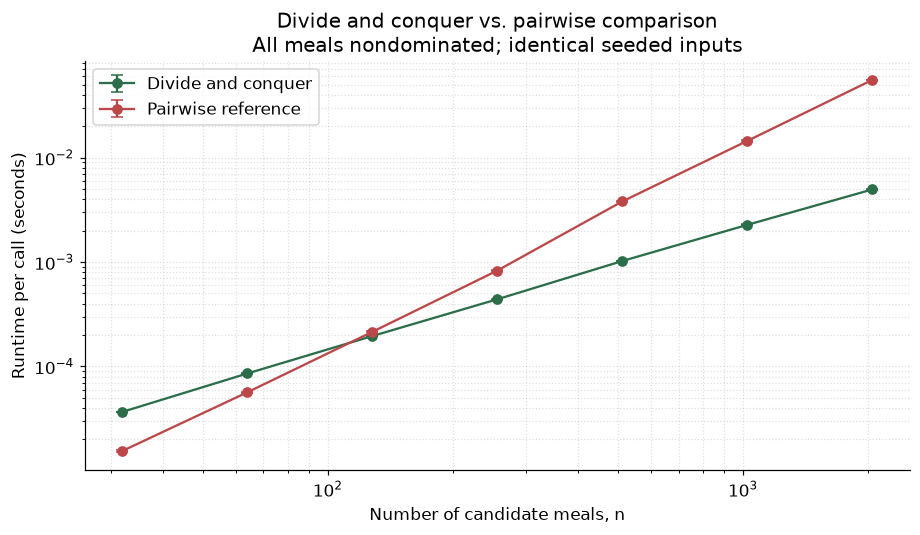

In [13]:
BASELINE_SIZES = [2**power for power in range(5, 12)]
baseline_raw = benchmark(BASELINE_SIZES, ["all_frontier"],
                         SEED_COUNT, REPEATS, MASTER_SEED,
                         include_brute_force=True)
baseline_per_seed, baseline_summary = summarize_timings(baseline_raw)
baseline_raw.to_csv(OUTPUT_DIR / "baseline_raw.csv", index=False)
baseline_per_seed.to_csv(OUTPUT_DIR / "baseline_per_seed.csv", index=False)
baseline_summary.to_csv(OUTPUT_DIR / "baseline_summary.csv", index=False)
display(baseline_summary)
fig = plot_baseline(baseline_summary, OUTPUT_DIR)
plt.show()
plt.close(fig)

## 8. Measured results and report exports

The next cell derives the reported values from the measurements above, writes
machine-readable results and environment metadata, and creates a LaTeX section
with the two main figures. This replaces the earlier future-tense experimental
plan. Review the generated text alongside the plots: an empirical trend supports
the analysis but does not prove it, and the meal example is still hypothetical.

In [14]:
worst, fitted_k = fit_reference(runtime_summary)
largest = worst.iloc[-1]
ratios = worst.mean_seconds.to_numpy() / (
    worst.n.to_numpy() * np.log2(worst.n.to_numpy()))
last_baseline = baseline_summary[baseline_summary.n == max(BASELINE_SIZES)]
dc_seconds = float(last_baseline[last_baseline.algorithm == "divide_and_conquer"].mean_seconds.iloc[0])
bf_seconds = float(last_baseline[last_baseline.algorithm == "brute_force"].mean_seconds.iloc[0])
metrics = {
    "validated_cases": validation_results["total_cases"],
    "selected_example_ids": [m.meal_id for m in example_frontier],
    "largest_n": int(largest.n),
    "largest_worst_case_mean_seconds": float(largest.mean_seconds),
    "largest_worst_case_std_seconds": float(largest.std_seconds),
    "fitted_k_seconds": fitted_k,
    "normalized_min_ns": float(min(ratios) * 1e9),
    "normalized_max_ns": float(max(ratios) * 1e9),
    "baseline_n": max(BASELINE_SIZES),
    "baseline_dc_seconds": dc_seconds,
    "baseline_pairwise_seconds": bf_seconds,
    "baseline_pairwise_over_dc_ratio": bf_seconds / dc_seconds,
    "main_timed_batches": len(runtime_raw),
    "baseline_timed_batches": len(baseline_raw),
}
metadata.update({
    "experiment_finished": datetime.now(ZoneInfo("America/New_York")).isoformat(),
    "baseline_sizes": BASELINE_SIZES,
    "timing_csv_sha256": {name: hashlib.sha256((OUTPUT_DIR / name).read_bytes()).hexdigest()
        for name in ("runtime_raw.csv", "runtime_summary.csv", "baseline_raw.csv", "baseline_summary.csv")},
})
(OUTPUT_DIR / "experiment_metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
(OUTPUT_DIR / "results.json").write_text(json.dumps(metrics, indent=2) + "\n")
display(pd.DataFrame([metrics]).T.rename(columns={0: "value"}))

report = rf"""
% Generated from executed measurements. Upload both PNG files beside your main.tex.
\subsection{{Implementation and Runtime Analysis}}

We implemented the divide-and-conquer meal-frontier algorithm in Python
{platform.python_version()} and ran the experiments in a Jupyter notebook.
Costs are represented in integer cents and protein amounts in integer
milligrams. Distinct meal identifiers with identical nondominated values
are retained. The implementation passed {validation_results['total_cases']:,}
validation cases, including exhaustive small inputs, randomized comparisons
against a pairwise reference, and invalid-input checks.

Figure~\ref{{fig:meal-frontier-example}} shows the hypothetical eight-meal
example used to illustrate the algorithm. The returned frontier contains
C, E, A, D, and H; meals B, F, and G are dominated. These values illustrate
the method and are not collected food-price or nutrient measurements.

We measured inputs ranging from {min(SIZES):,} to {max(SIZES):,} meals,
using seven seeded instances per size and input family. Each instance
was measured in three calibrated batches after a warm-up call. We used
the median per-call batch time for each instance and plotted the mean
and sample standard deviation across the seven instances. Input generation,
file operations, and plotting were excluded; input validation and the
complete frontier computation were included. Job order was randomized,
and cyclic garbage collection was disabled during timing.

The input families were all-nondominated trade-offs, independent random
cost and protein values, and a dominance chain with one surviving meal.
The all-nondominated family exercises the worst case because every meal
survives every recursion level. Figure~\ref{{fig:meal-frontier-runtime}}
compares its measured runtimes with $k n\log_2 n$, where one constant
$k$ was fitted by least squares through the origin across all input sizes.

At $n={int(largest.n)}$, the mean worst-case runtime was
{float(largest.mean_seconds) * 1000:.3f} ms, with a sample standard deviation
of {float(largest.std_seconds) * 1000:.3f} ms. Across the measured sizes,
the normalized mean $t(n)/(n\log_2 n)$ ranged from
{min(ratios) * 1e9:.1f} to {max(ratios) * 1e9:.1f} nanoseconds.
The notebook includes the normalized plot and comparisons between input
families so that deviations from the reference are visible.

On the all-nondominated inputs with $n={max(BASELINE_SIZES)}$, the pairwise
reference averaged {bf_seconds * 1000:.3f} ms and divide and conquer averaged
{dc_seconds * 1000:.3f} ms, a measured ratio of {bf_seconds / dc_seconds:.2f}.
These are observations on this execution environment, not universal
performance guarantees. The experiments complement the theoretical
analysis and do not constitute a proof of an asymptotic bound.

\begin{{figure*}}[t]
    \centering
    \includegraphics[width=0.95\textwidth]{{before_after_meals.png}}
    \caption{{Hypothetical meal options before and after frontier computation.
    The connecting line is a visual guide between available meals.}}
    \label{{fig:meal-frontier-example}}
\end{{figure*}}

\begin{{figure}}[t]
    \centering
    \includegraphics[width=\linewidth]{{runtime_nlogn.png}}
    \caption{{Measured worst-case runtime (green mean and sample standard
    deviation) and a scaled $n\log_2 n$ reference (red).}}
    \label{{fig:meal-frontier-runtime}}
\end{{figure}}
""".strip()
(OUTPUT_DIR / "report_results.tex").write_text(report + "\n")
print("Saved figures, raw timing CSVs, metadata, results, and report_results.tex.")
print("Retain this chat's exact prompts and responses for the required AI-use appendix.")

,value
validated_cases,7699
selected_example_ids,"[C, E, A, D, H]"
largest_n,131072
largest_worst_case_mean_seconds,0.505231
largest_worst_case_std_seconds,0.00165
fitted_k_seconds,0.0
normalized_min_ns,213.399145
normalized_max_ns,228.103998
baseline_n,2048
baseline_dc_seconds,0.004948


Saved figures, raw timing CSVs, metadata, results, and report_results.tex.
Retain this chat's exact prompts and responses for the required AI-use appendix.
